In [97]:
import numpy as np  
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [98]:
df = pd.read_csv('./datasets/dirty_cafe_sales.csv    ')
df

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02


In [99]:
df.shape

(10000, 8)

In [100]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 1.1 MB


In [101]:
missing_values = df.isnull().sum()
Mv_percentage = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({'Missing_values':missing_values,'Missing_values_percentage':Mv_percentage})
missing_df = missing_df[missing_df['Missing_values']>0]
missing_df


,Missing_values,Missing_values_percentage
Item,333,3.33
Quantity,138,1.38
Price Per Unit,179,1.79
Total Spent,173,1.73
Payment Method,2579,25.79
Location,3265,32.65
Transaction Date,159,1.59


In [102]:
df.duplicated().sum()

np.int64(0)

In [103]:
df.tail(200)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9800,TXN_2954833,Coffee,1,2.0,2.0,NaN,NaN,2023-01-29
9801,TXN_5309677,Coffee,4,2.0,8.0,Cash,In-store,2023-08-09
9802,TXN_6011106,Juice,2,3.0,6.0,Digital Wallet,NaN,2023-09-07
9803,TXN_4714592,Tea,1,1.5,1.5,Cash,NaN,2023-06-02
9804,TXN_6704284,Salad,2,5.0,10.0,Credit Card,Takeaway,2023-08-31
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02


In [104]:
df.dtypes

Transaction ID      str
Item                str
Quantity            str
Price Per Unit      str
Total Spent         str
Payment Method      str
Location            str
Transaction Date    str
dtype: object

In [105]:
df['Transaction Date'].isna().mean() * 100

np.float64(1.59)

In [106]:
df['Transaction Date']= pd.to_datetime(df['Transaction Date'],format = '%Y-%m-%d', errors = 'coerce')

In [107]:
df['Transaction Date'].agg(['min', 'max'])

min   2023-01-01
max   2023-12-31
Name: Transaction Date, dtype: datetime64[us]

In [108]:
df['Transaction Date'].dt.year.value_counts().sort_index()

Transaction Date
2023.0    9540
Name: count, dtype: int64

In [109]:
df.loc[
    df['Transaction Date'].isna(),
    ['Transaction ID', 'Transaction Date']
].head(20)

,Transaction ID,Transaction Date
11,TXN_3051279,NaT
29,TXN_7640952,NaT
33,TXN_7710508,NaT
77,TXN_2091733,NaT
103,TXN_7028009,NaT
104,TXN_7447872,NaT
115,TXN_1001832,NaT
142,TXN_7943008,NaT
160,TXN_1093800,NaT
175,TXN_6463132,NaT


In [110]:
df['Quantity'].describe()

count     9862
unique       7
top          5
freq      2013
Name: Quantity, dtype: object

In [111]:

df['Quantity'].value_counts().sort_index()

Quantity
1          1822
2          1974
3          1849
4          1863
5          2013
ERROR       170
UNKNOWN     171
Name: count, dtype: int64

In [112]:
df['Quantity'] = pd.to_numeric(
    df['Quantity'], errors='coerce'
)

<Axes: >

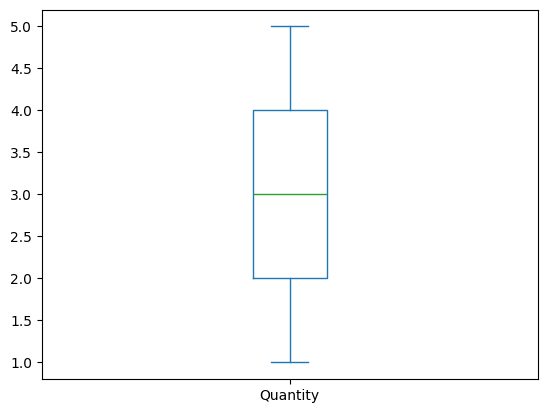

In [113]:
df['Quantity'].plot(kind='box')

In [114]:
Q1 = df['Quantity'].quantile(0.25)
Q3 = df['Quantity'].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 2.0
Q3: 4.0
IQR: 2.0


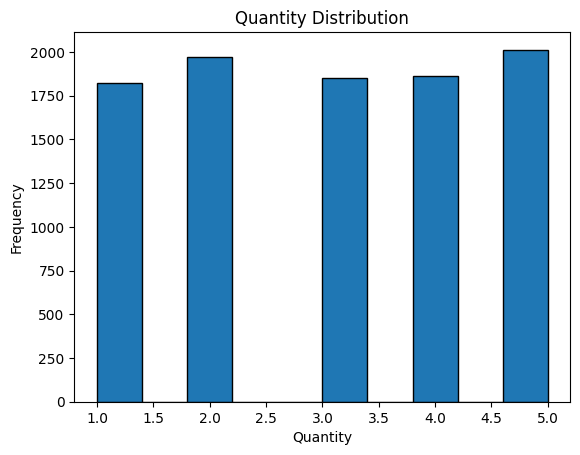

In [115]:
import matplotlib.pyplot as plt

df['Quantity'].plot(kind='hist', bins=10, edgecolor='black')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.title('Quantity Distribution')
plt.show()

In [116]:
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median()).astype('int')

<Axes: >

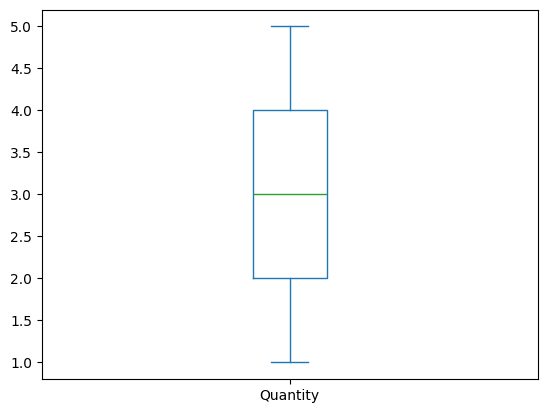

In [117]:
df['Quantity'].plot(kind='box')

In [118]:
df.tail(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9990,TXN_1538510,Coffee,5,2.0,10.0,Digital Wallet,NaN,2023-05-22
9991,TXN_3897619,Sandwich,3,4.0,12.0,Cash,Takeaway,2023-02-24
9992,TXN_2739140,Smoothie,4,4.0,16.0,UNKNOWN,In-store,2023-07-05
9993,TXN_4766549,Smoothie,2,4.0,NaN,Cash,NaN,2023-10-20
9994,TXN_7851634,UNKNOWN,4,4.0,16.0,NaN,NaN,2023-01-08
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02
9999,TXN_6170729,Sandwich,3,4.0,12.0,Cash,In-store,2023-11-07


In [119]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    10000 non-null  str           
 1   Item              9667 non-null   str           
 2   Quantity          10000 non-null  int64         
 3   Price Per Unit    9821 non-null   str           
 4   Total Spent       9827 non-null   str           
 5   Payment Method    7421 non-null   str           
 6   Location          6735 non-null   str           
 7   Transaction Date  9540 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(1), str(6)
memory usage: 974.4 KB


In [120]:
df['Price Per Unit'] = pd.to_numeric(df['Price Per Unit'], errors = 'coerce')
df['Total Spent'] = pd.to_numeric(df['Total Spent'], errors = 'coerce')


In [121]:
df.isnull().sum()

Transaction ID         0
Item                 333
Quantity               0
Price Per Unit       533
Total Spent          502
Payment Method      2579
Location            3265
Transaction Date     460
dtype: int64

In [122]:
df['Item'].isnull().sum()

np.int64(333)

In [123]:
df.columns[df.isnull().any()].tolist()

['Item',
 'Price Per Unit',
 'Total Spent',
 'Payment Method',
 'Location',
 'Transaction Date']

In [124]:
df

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02


In [125]:
df.groupby(['Item', 'Price Per Unit']).size().reset_index(name='Count')

,Item,Price Per Unit,Count
0,Cake,3.0,1085
1,Coffee,2.0,1108
2,Cookie,1.0,1026
3,ERROR,1.0,34
4,ERROR,1.5,37
5,ERROR,2.0,31
6,ERROR,3.0,77
7,ERROR,4.0,61
8,ERROR,5.0,39
9,Juice,3.0,1110


In [126]:
df.groupby('Item')['Price Per Unit'].nunique().sort_values(ascending=False)


Item
UNKNOWN     6
ERROR       6
Coffee      1
Cake        1
Juice       1
Cookie      1
Salad       1
Sandwich    1
Smoothie    1
Tea         1
Name: Price Per Unit, dtype: int64

In [127]:
df.groupby('Item')['Price Per Unit'].nunique()

Item
Cake        1
Coffee      1
Cookie      1
ERROR       6
Juice       1
Salad       1
Sandwich    1
Smoothie    1
Tea         1
UNKNOWN     6
Name: Price Per Unit, dtype: int64

In [128]:
df.groupby('Item')['Price Per Unit'].agg(
    ['count', 'nunique', 'min', 'max']
)

,count,nunique,min,max
Item,,,,
Cake,1085,1,3.0,3.0
Coffee,1108,1,2.0,2.0
Cookie,1026,1,1.0,1.0
ERROR,279,6,1.0,5.0
Juice,1110,1,3.0,3.0
Salad,1082,1,5.0,5.0
Sandwich,1082,1,4.0,4.0
Smoothie,1036,1,4.0,4.0
Tea,1023,1,1.5,1.5


In [129]:
df[df['Item'].isin(['ERROR', 'UNKNOWN'])][
    ['Item', 'Price Per Unit', 'Quantity', 'Total Spent']
].head(20)

,Item,Price Per Unit,Quantity,Total Spent
6,UNKNOWN,3.0,3,9.0
14,ERROR,1.5,2,3.0
31,UNKNOWN,1.0,2,NaN
33,UNKNOWN,1.0,5,5.0
36,UNKNOWN,3.0,4,12.0
52,UNKNOWN,5.0,5,25.0
63,UNKNOWN,5.0,3,15.0
69,ERROR,3.0,5,15.0
88,ERROR,5.0,1,5.0
91,UNKNOWN,3.0,5,15.0


In [130]:
df[df['Item'].isin(['ERROR', 'UNKNOWN'])].groupby(
    ['Item', 'Price Per Unit']
).size().reset_index(name='Count')

,Item,Price Per Unit,Count
0,ERROR,1.0,34
1,ERROR,1.5,37
2,ERROR,2.0,31
3,ERROR,3.0,77
4,ERROR,4.0,61
5,ERROR,5.0,39
6,UNKNOWN,1.0,45
7,UNKNOWN,1.5,40
8,UNKNOWN,2.0,49
9,UNKNOWN,3.0,77


In [131]:
df[df['Item'].isin(['ERROR', 'UNKNOWN'])].groupby(
    ['Item', 'Payment Method']
).size().unstack(fill_value=0)

Payment Method,Cash,Credit Card,Digital Wallet,ERROR,UNKNOWN
Item,,,,,
ERROR,62,72,67,4,8
UNKNOWN,76,77,77,11,15


In [132]:
df[df['Item'].isin(['ERROR', 'UNKNOWN'])].groupby(
    ['Item', 'Location']
).size().unstack(fill_value=0)

Location,ERROR,In-store,Takeaway,UNKNOWN
Item,,,,
ERROR,11,87,87,12
UNKNOWN,11,98,105,9


In [133]:
df['Item'] = df['Item'].replace({
    'ERROR': 'Unknown',
    'UNKNOWN': 'Unknown'
})

df['Payment Method'] = df['Payment Method'].replace({
    'ERROR': 'Unknown',
    'UNKNOWN': 'Unknown'
})

In [134]:
df['Item'].value_counts(dropna=False)

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
Unknown      636
NaN          333
Name: count, dtype: int64

In [135]:
df['Payment Method'].value_counts(dropna=False)

Payment Method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
Unknown            599
Name: count, dtype: int64

In [136]:
df.groupby('Price Per Unit')['Item'].unique()

Price Per Unit
1.0                [Cookie, Unknown, nan]
1.5                   [Unknown, Tea, nan]
2.0                [Coffee, nan, Unknown]
3.0           [Cake, Unknown, nan, Juice]
4.0    [Smoothie, Sandwich, Unknown, nan]
5.0                 [Salad, Unknown, nan]
Name: Item, dtype: object

In [137]:

df_clean = df.copy()


mask = df_clean['Item'].isna()


price_to_item = {
    1.0: 'Cookie',
    1.5: 'Tea',
    2.0: 'Coffee',
    5.0: 'Salad'
}


df_clean.loc[mask, 'Item'] = (
    df_clean.loc[mask, 'Price Per Unit']
    .map(price_to_item)
    .fillna(df_clean.loc[mask, 'Item'])
)

In [138]:
df_clean.isnull().sum()

Transaction ID         0
Item                 185
Quantity               0
Price Per Unit       533
Total Spent          502
Payment Method      2579
Location            3265
Transaction Date     460
dtype: int64

In [139]:
df_clean['Item'].value_counts(dropna=False)

Item
Coffee      1204
Salad       1186
Juice       1171
Cake        1139
Sandwich    1131
Cookie      1130
Tea         1122
Smoothie    1096
Unknown      636
NaN          185
Name: count, dtype: int64

In [140]:
df_clean['Item'].isna().sum()

np.int64(185)

In [141]:
df_clean[
    df_clean['Item'].isna()
][['Price Per Unit']].value_counts(dropna=False)

Price Per Unit
4.0               82
3.0               80
NaN               23
Name: count, dtype: int64

In [142]:
df_clean

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02


In [143]:
df_clean['Price Per Unit'].isna().sum()

np.int64(533)

In [144]:
df_clean['Price Per Unit'] = (
    df_clean['Price Per Unit'].fillna(
        df_clean['Total Spent'] / df_clean['Quantity']
    )
)

In [145]:
df_clean['Price Per Unit'].isna().sum()

np.int64(20)

In [146]:
df_clean

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,1.0,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,1.0,3.0,Digital Wallet,NaN,2023-12-02


In [147]:
df_clean['Total Spent'].isna().sum()

np.int64(502)

In [148]:
df_clean.loc[
    df_clean['Price Per Unit'].isna(),
    ['Price Per Unit', 'Total Spent', 'Quantity']
].isna().sum()

Price Per Unit    20
Total Spent       20
Quantity           0
dtype: int64

In [149]:
df_clean.loc[
    df_clean['Price Per Unit'].isna(),
    ['Price Per Unit', 'Total Spent', 'Quantity']
].head(10)

,Price Per Unit,Total Spent,Quantity
65,NaN,NaN,3
1674,NaN,NaN,2
1761,NaN,NaN,4
2229,NaN,NaN,2
2289,NaN,NaN,4
2585,NaN,NaN,3
3162,NaN,NaN,3
3598,NaN,NaN,1
3673,NaN,NaN,2
4021,NaN,NaN,2


In [150]:
df_clean['Price Per Unit'] = (
    df_clean['Price Per Unit']
    .fillna(
        df_clean.groupby('Item')['Price Per Unit']
        .transform('first')
    )
)

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='str')

In [151]:
df_clean['Price Per Unit'].isna().sum()

np.int64(1)

In [152]:
df_clean['Price Per Unit']

0       2.0
1       3.0
2       1.0
3       5.0
4       2.0
       ... 
9995    2.0
9996    1.0
9997    2.0
9998    1.0
9999    4.0
Name: Price Per Unit, Length: 10000, dtype: float64

In [153]:
df_clean.loc[
    df_clean['Price Per Unit'].isna(),
    ['Item', 'Price Per Unit', 'Quantity', 'Total Spent']
]

,Item,Price Per Unit,Quantity,Total Spent
1761,NaN,NaN,4,NaN


In [154]:
df_clean.loc[[1761,4003, 4831, 6292,9662]]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
1761,TXN_3611851,NaN,4,NaN,NaN,Credit Card,NaN,2023-02-09
4003,TXN_6119612,NaN,3,3.0,NaN,Cash,NaN,2023-12-25
4831,TXN_5926025,NaN,2,4.0,NaN,Digital Wallet,NaN,2023-07-29
6292,TXN_6884558,NaN,1,3.0,NaN,Cash,In-store,2023-08-14
9662,TXN_8860270,NaN,1,4.0,4.0,Cash,Takeaway,2023-11-06


In [155]:
df_clean.loc[[1761,4003, 4831, 6292]] = df_clean.loc[[1761,4003, 4831, 6292]].ffill().bfill()

In [156]:
df.columns

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='str')

In [157]:
df_clean[['Item', 'Quantity', 'Price Per Unit', 'Total Spent']].isna().sum()

Item              185
Quantity            0
Price Per Unit      0
Total Spent       502
dtype: int64

In [158]:
df_clean['Total Spent']=df_clean['Total Spent'].fillna(df_clean['Price Per Unit'] * df_clean['Quantity'])

In [159]:
df_clean[['Item', 'Quantity', 'Price Per Unit', 'Total Spent']].isna().sum()

Item              185
Quantity            0
Price Per Unit      0
Total Spent         0
dtype: int64

In [160]:
price_to_item = {
    1.0: 'Cookie',
    1.5: 'Tea',
    2.0: 'Coffee',
    5.0: 'Salad'
}

mask = df_clean['Item'].isna()

df_clean.loc[mask, 'Item'] = (
    df_clean.loc[mask, 'Price Per Unit']
    .map(price_to_item)
    .fillna(df_clean.loc[mask, 'Item'])
)

In [161]:
df_clean[['Item', 'Quantity', 'Price Per Unit', 'Total Spent']].isna().sum()

Item              176
Quantity            0
Price Per Unit      0
Total Spent         0
dtype: int64

In [162]:
df_clean[df_clean['Price Per Unit'].isin([3.0, 4.0])]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,Unknown,3,3.0,9.0,Unknown,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
...,...,...,...,...,...,...,...,...
9991,TXN_3897619,Sandwich,3,4.0,12.0,Cash,Takeaway,2023-02-24
9992,TXN_2739140,Smoothie,4,4.0,16.0,Unknown,In-store,2023-07-05
9993,TXN_4766549,Smoothie,2,4.0,8.0,Cash,NaN,2023-10-20
9994,TXN_7851634,Unknown,4,4.0,16.0,NaN,NaN,2023-01-08


In [163]:
df_clean[df_clean['Item'].isna()]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
8,TXN_4717867,NaN,5,3.000000,15.0,NaN,Takeaway,2023-07-28
61,TXN_8051289,NaN,1,3.000000,3.0,NaN,In-store,2023-10-09
151,TXN_4031509,NaN,4,4.000000,16.0,Credit Card,Takeaway,2023-01-04
168,TXN_3494565,NaN,2,4.000000,8.0,Unknown,NaN,2023-07-10
197,TXN_5115080,NaN,5,3.000000,15.0,Credit Card,NaN,2023-02-18
...,...,...,...,...,...,...,...,...
9662,TXN_8860270,NaN,1,4.000000,4.0,Cash,Takeaway,2023-11-06
9771,TXN_9582818,NaN,1,4.000000,4.0,Cash,In-store,2023-10-27
9819,TXN_1208561,NaN,3,6.666667,20.0,Credit Card,NaN,2023-08-19
9820,TXN_8751702,NaN,5,3.000000,15.0,Cash,NaN,2023-02-13


In [164]:
df_clean.loc[[9662,1761,4003, 4831, 6292]]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9662,TXN_8860270,NaN,1,4.0,4.0,Cash,Takeaway,2023-11-06
1761,TXN_3611851,NaN,4,3.0,12.0,Credit Card,In-store,2023-02-09
4003,TXN_6119612,NaN,3,3.0,9.0,Cash,In-store,2023-12-25
4831,TXN_5926025,NaN,2,4.0,8.0,Digital Wallet,In-store,2023-07-29
6292,TXN_6884558,NaN,1,3.0,3.0,Cash,In-store,2023-08-14


In [165]:
df.loc[
    [9819]
]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9819,TXN_1208561,NaN,3,NaN,20.0,Credit Card,NaN,2023-08-19


In [166]:
df_clean['Item'].value_counts(dropna=False)

Item
Coffee      1208
Salad       1186
Juice       1171
Cake        1139
Cookie      1132
Sandwich    1131
Tea         1125
Smoothie    1096
Unknown      636
NaN          176
Name: count, dtype: int64

In [167]:
df_clean.isna().sum()

Transaction ID         0
Item                 176
Quantity               0
Price Per Unit         0
Total Spent            0
Payment Method      2579
Location            3262
Transaction Date     460
dtype: int64

In [174]:

df_clean['Payment Method'] = df_clean['Payment Method'].fillna(
    df_clean['Payment Method'].mode()[0]
)

In [175]:
df_clean.loc[9995]

Transaction ID              TXN_7672686
Item                             Coffee
Quantity                              2
Price Per Unit                      2.0
Total Spent                         4.0
Payment Method           Digital Wallet
Location                        UNKNOWN
Transaction Date    2023-08-30 00:00:00
Name: 9995, dtype: object

In [176]:
df_clean['Payment Method'].isna().sum()

np.int64(0)

In [186]:
df_clean['Item'] = df_clean['Item'].replace('ERROR', 'Unknown')
df_clean['Item'] = df_clean['Item'].fillna('Unknown')
df_clean['Transaction Date'] = df_clean['Transaction Date'].fillna('Unknown')
df_clean['Location'] = df_clean['Location'].fillna('Unknown')


In [187]:
df_clean.isna().sum()

Transaction ID      0
Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64

In [188]:
df = df_clean

In [189]:
df.isna().sum()

Transaction ID      0
Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64